# 1.2 Mempelajari Penggunaan Driver Neo4J

In [6]:
from neo4j import GraphDatabase

URI = "bolt://127.0.0.1:7687"
AUTH = ("neo4j", "Pmtkpi66") 

driver = GraphDatabase.driver(URI, auth=AUTH)
driver.verify_connectivity()

print("Koneksi Berhasil! Database Neo4j siap dipakai.")

driver.close()

Koneksi Berhasil! Database Neo4j siap dipakai.


In [7]:
from neo4j import GraphDatabase, RoutingControl

def add_friend(driver, name, friend_name):
    driver.execute_query(
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)",
        name=name, friend_name=friend_name, database_="neo4j"
    )

def print_friends(driver, name):
    records, _, _ = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
        "RETURN friend.name ORDER BY friend.name",
        name=name, database_="neo4j", routing_=RoutingControl.READ
    )
    for record in records:
        print(record["friend.name"])

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")
    print_friends(driver, "Arthur")

Guinevere
Lancelot
Merlin


**Pertanyaan Pendahuluan (Checkpoint)**

1. **Apa nama database yang digunakan pada tutorial ini?**

   Jawab: Database bernama `neo4j` (terlihat dari parameter `database_="neo4j"` pada kode).

2. **Sebutkan akses lain (seperti sintaks DDL/DML CYPHER) yang dapat digunakan mengakses database lain dalam 1 instance!**

   Jawab: Menggunakan klausa `USE <nama_database>` di awal query Cypher, atau dengan menentukan parameter `database` saat inisialisasi session di driver Python.

3. **Apa jenis graf pertenanan yang telah dibuat di sini?**

   Jawab: Graf berarah (Directed Graph) dengan tipe relasi `KNOWS` antar simpul `Person`.

## CYPHER Total Reset

In [8]:
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    with driver.session() as session:
        session.run("MATCH (n) DETACH DELETE n")
        
print("Database berhasil di-reset. Semua data lama sudah dihapus.")

Database berhasil di-reset. Semua data lama sudah dihapus.


# 1.3 Memahami Fitur Dataset RetailRocket
Note:
- `timestamp`: Waktu dalam format unix epoch.
- `visitorid`: ID unik pengunjung.
- `event`: Jenis interaksi default: view, addtocart, transaction.
- `itemid`: ID unik produk.
- `transactionid`: ID transaksi, hanya terisi saat event berjenis 'transaction'.

In [9]:
import pandas as pd

df = pd.read_csv('data/events.csv')
df.head()

,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN


In [10]:
from neo4j import GraphDatabase

driver = GraphDatabase.driver(URI, auth=AUTH)
session = driver.session(database="system")

In [11]:
import argparse

def parse_arguments():
    parser = argparse.ArgumentParser(
        description="Impor dataset RetailRocket (events.csv) ke database Neo4J."
    )
    parser.add_argument(
        "-u", "--user", default="neo4j", help="Username Neo4j (default: neo4j)"
    )
    parser.add_argument(
        "-p",
        "--password",
        default="Pmtkpi66",
        help="Password Neo4J (default: neo4j)",
    )
    parser.add_argument(
        "-b",
        "--bolt",
        default="neo4j://127.0.0.1:7687",
        help="Neo4J URI / Bolt (default: neo4j://127.0.0.1:7687)",
    )
    parser.add_argument(
        "-s",
        "--source",
        default="data",
        help="Direktori/folder sumber data (default: data)",
    )
    return parser.parse_args([])

In [12]:
import os
import sys

args = parse_arguments() 

csv_file_path = os.path.join(args.source, "events.csv")

if not os.path.exists(csv_file_path):
    print(f"Error: File '{csv_file_path}' tidak ditemukan!")
    sys.exit(1)

In [13]:
try: 
    driver = GraphDatabase.driver(
        args.bolt, auth=(args.user, args.password)
    )
    driver.verify_connectivity()
except Exception as e:
    print(f"Gagal terhubung ke database: {e}")
    sys.exit(1)

In [14]:
def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})
    WITH v, i, row
    CALL {
      WITH v, i, row
      WITH v, i, row WHERE row.event = 'view'
      CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)

      UNION ALL

      WITH v, i, row
      WITH v, i, row WHERE row.event = 'addtocart'
      CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)

      UNION ALL

      WITH v, i, row
      WITH v, i, row WHERE row.event = 'transaction'
      CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
    }
    """
    tx.run(cypher_query, batch=batch)

In [17]:
import pandas as pd
from tqdm import tqdm

batch_size = 10000 
total_rows = len(pd.read_csv(csv_file_path, usecols=[0])) 

def create_constraints(session):
    session.run("CREATE CONSTRAINT IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE")
    session.run("CREATE CONSTRAINT IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE")
with driver.session() as session:
    create_constraints(session)

    print(f"Membaca file data dari: {csv_file_path}")
    chunks = pd.read_csv(csv_file_path, chunksize=batch_size)

    total_chunks = (total_rows // batch_size) + 1

    print("Memulai proses impor data ke Neo4j...")
    for chunk in tqdm(
        chunks, total=total_chunks, desc="Mengimpor Batch Data"
    ):
        # Membersihkan data null/NaN pada transactionid
        chunk["transactionid"] = (
            chunk["transactionid"].fillna("").astype(str)
        )

        records = chunk.to_dict(orient="records")
        session.execute_write(import_batch, records)

driver.close()
print("Proses impor berhasil.")

Membaca file data dari: data\events.csv
Memulai proses impor data ke Neo4j...


Mengimpor Batch Data: 100%|██████████| 276/276 [04:39<00:00,  1.01s/it]

Proses impor berhasil.


In [20]:
URI = "bolt://127.0.0.1:7687"
AUTH = ("neo4j", "Pmtkpi66")
driver = GraphDatabase.driver(URI, auth=AUTH)

with driver.session() as session:
    # 1. Hitung Visitor
    visitor_count = session.run("MATCH (v:Visitor) RETURN count(v) AS c").single()["c"]
    
    # 2. Hitung Item
    item_count = session.run("MATCH (i:Item) RETURN count(i) AS c").single()["c"]
    
    # 3. Hitung Interaksi (Edge)
    edge_count = session.run("MATCH ()-[r]->() RETURN count(r) AS c").single()["c"]

    print("HASIL IMPOR DATASET RETAIL ROCKET:")
    print(f"• Total Visitor (Node) : {visitor_count:,}")
    print(f"• Total Item (Node)    : {item_count:,}")
    print(f"• Total Interaksi (Edge): {edge_count:,}")

HASIL IMPOR DATASET RETAIL ROCKET:
• Total Visitor (Node) : 1,407,580
• Total Item (Node)    : 235,061
• Total Interaksi (Edge): 2,756,101


# 2.1 Wrangling dan EDA

#### 1. Tentukan 2 periode waktu sebagai filter dari data interaksi

Periode: P1 (16–31 Juli 2015) | P2 (01–18 Sept 2015)

#### 2. Filter Data P1 dan P2

In [21]:
import pandas as pd

df = pd.read_csv("data/events.csv")

Konversi timestamp (milidetik) ke format tanggal yang bisa dibaca

In [22]:
df["datetime"] = pd.to_datetime(df["timestamp"], unit="ms")

Tentukan Periode Waktu (P1 (16–31 Juli 2015) | P2 (01–18 Sept 2015))

In [23]:
start_p1 = pd.Timestamp("2015-07-16 00:00:00")
end_p1 = pd.Timestamp("2015-07-31 23:59:59")

start_p2 = pd.Timestamp("2015-09-01 00:00:00")
end_p2 = pd.Timestamp("2015-09-18 23:59:59")

Lakukan Filter

In [24]:
df_p1 = df[(df["datetime"] >= start_p1) & (df["datetime"] <= end_p1)]
df_p2 = df[(df["datetime"] >= start_p2) & (df["datetime"] <= end_p2)]

Simpan ke file CSV baru

In [25]:
df_p1.to_csv("data/events_p1.csv", index=False)
df_p2.to_csv("data/events_p2.csv", index=False)

Tampilkan hasil

In [26]:
print("Filter Selesai!")
print(f"Jumlah baris P1 (16-31 Juli 2015): {len(df_p1)} baris")
print(f"Jumlah baris P2 (01-18 Sept 2015): {len(df_p2)} baris")

Filter Selesai!
Jumlah baris P1 (16-31 Juli 2015): 364206 baris
Jumlah baris P2 (01-18 Sept 2015): 303710 baris


#### 3. Lakukan query untuk mendapatkan komposisi dari subgraph yang dibuat. Uraikan jenis simpul dan jumlah masing-masing simpul dengan Python API! Jelaskan CYPHER SQL yang digunakan!

In [27]:
with driver.session() as session:
    session.run("""
        MATCH (n) 
        CALL { 
            WITH n 
            DETACH DELETE n 
        } IN TRANSACTIONS OF 10000 ROWS
    """)
print("Database berhasil dikosongkan secara bertahap.")

Received notification from DBMS server: <GqlStatusObject gql_status='01N00', status_description='warn: feature deprecated. CALL subquery without a variable scope clause is deprecated. Use CALL (n) { ... }', position=<SummaryInputPosition line=3, column=9, offset=28>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 28, 'line': 3, 'column': 9}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: '\n        MATCH (n) \n        CALL { \n            WITH n \n            DETACH DELETE n \n        } IN TRANSACTIONS OF 10000 ROWS\n    '


Database berhasil dikosongkan secara bertahap.


Querry

In [28]:
import pandas as pd
from tqdm import tqdm

csv_p1 = "data/events_p1.csv"
batch_size = 10000
total_rows_p1 = len(pd.read_csv(csv_p1, usecols=[0]))
total_chunks_p1 = (total_rows_p1 // batch_size) + 1

with driver.session() as session:
    create_constraints(session)
    print(f"Membaca file data dari: {csv_p1}")
    chunks = pd.read_csv(csv_p1, chunksize=batch_size)
    
    print("Memulai proses impor data P1 ke Neo4j...")
    for chunk in tqdm(chunks, total=total_chunks_p1, desc="Mengimpor P1"):
        chunk["transactionid"] = chunk["transactionid"].fillna("").astype(str)
        records = chunk.to_dict(orient="records")
        session.execute_write(import_batch, records)
        
print("Proses impor P1 berhasil.")

Membaca file data dari: data/events_p1.csv
Memulai proses impor data P1 ke Neo4j...


Mengimpor P1: 100%|██████████| 37/37 [00:41<00:00,  1.13s/it]

Proses impor P1 berhasil.


#### 4. Lakukan Vector Space Modelling (VSM) terhadap simpul yang diasumsikan sebagai User. Uraikan bagaimana karakteristiknya (dimensi, shape, plot networkx, dst.)

Mengambil data interaksi dari Neo4j

In [29]:
with driver.session() as session:
    query = """
    MATCH (v:Visitor)-[r]->(i:Item)
    RETURN v.visitorId AS visitorId, i.itemId AS itemId, count(r) AS interaksi
    """
    result = session.run(query)
    data = [record.data() for record in result]


Memasukkan ke DataFrame Pandas

In [30]:
pip install networkx matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [31]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix

In [32]:
df_interaksi = pd.DataFrame(data)


membuat Matriks VSM (Baris = User, Kolom = Item)

In [35]:
vsm_item = vsm_user.T

print("=== KARAKTERISTIK VSM ITEM ===")
print(f"Dimensi : 2 Dimensi (Baris=Item, Kolom=User)")
print(f"Shape   : {vsm_item.shape}")
print(f"Total Interaksi: {vsm_item.nnz:,} data")

=== KARAKTERISTIK VSM ITEM ===
Dimensi : 2 Dimensi (Baris=Item, Kolom=User)
Shape   : (88699, 199899)
Total Interaksi: 290,355 data


Menampilkan Karakteristik (Shape/Dimensi)

In [37]:
print(f"Total baris (Jumlah User) : {vsm_user.shape[0]} user")
print(f"Total kolom (Jumlah Item) : {vsm_user.shape[1]} item")
print(f"Dimensi Matriks (Shape)   : {vsm_user.shape}")
print("\nContoh 5 baris dan 5 kolom pertama matriks VSM User:")
# Menampilkan 5x5 pertama dari Sparse Matrix
print(vsm_user[:5, :5].toarray())

Total baris (Jumlah User) : 199899 user
Total kolom (Jumlah Item) : 88699 item
Dimensi Matriks (Shape)   : (199899, 88699)

Contoh 5 baris dan 5 kolom pertama matriks VSM User:
[[0 0 0 0 0]
 [0 0 0 0 0]
 [0 0 0 0 0]
 [0 0 0 0 0]
 [0 0 0 0 0]]


#### 5. Lakukan VSM terhadap simpul yang diasumsikan sebagai Item. Uraikan bagaimana karakteristiknya (dimensi, shape, plot networkx, dst.)!

Dimensi

In [39]:
print("Dimensi VSM Item: 2 Dimensi (Baris=Item, Kolom=User)")

Dimensi VSM Item: 2 Dimensi (Baris=Item, Kolom=User)


Shape

In [40]:
vsm_item = vsm_user.T
print("Shape VSM Item:", vsm_item.shape)

Shape VSM Item: (88699, 199899)


Plot Network

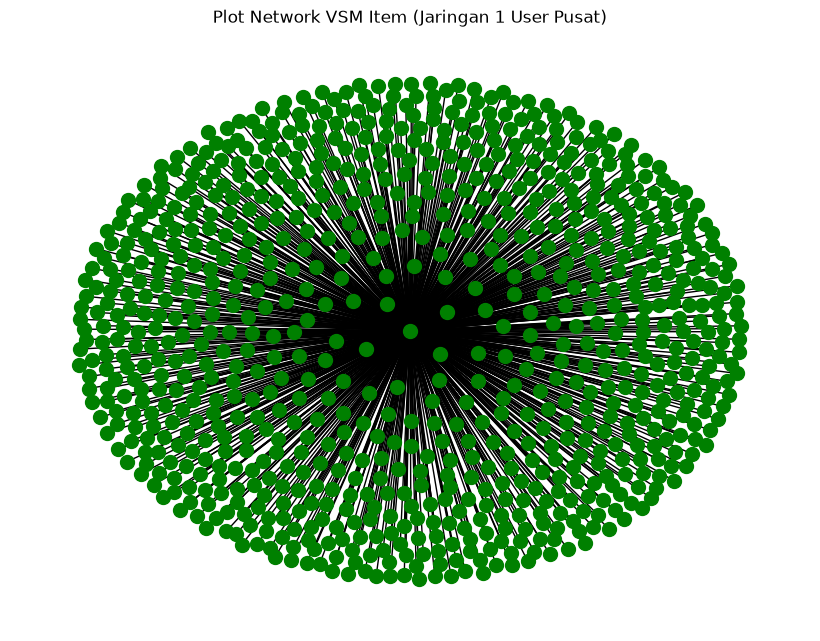

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt

# Ambil 5 User dengan interaksi terbanyak
top_5_users = df_interaksi['user_idx'].value_counts().index[:5]
# Filter data hanya untuk 5 user tersebut
df_visual = df_interaksi[df_interaksi['user_idx'].isin(top_5_users)]

G = nx.Graph()
G.add_edges_from(zip(df_visual['item_idx'], df_visual['user_idx']))

plt.figure(figsize=(10, 8))
# Pakai seed agar bentuknya rapi
pos = nx.spring_layout(G, seed=42) 
nx.draw(G, pos, node_size=50, node_color='green', with_labels=False)
plt.title("Plot Network VSM Item (Top 5 User)")
plt.show()

#### Berdasarkan eksplorasi no. 4 dan 5, uraikan proyeksi manakah yang lebih baik (efektif/efisien)!

proyeksi yang **lebih baik adalah VSM User**. 

Alasannya:
1. **Efisiensi Komputasi:** Meskipun jumlah User (199.899) lebih banyak dari Item (88.699), vektor pada VSM User memiliki dimensi/panjang yang lebih pendek (sepanjang 88.699). Sebaliknya, VSM Item memiliki vektor yang sangat panjang (sepanjang 199.899). Menghitung kemiripan dengan vektor yang lebih pendek (VSM User) jauh lebih ringan dan hemat RAM.
2. **Efektivitas Tujuan (KNN):** Pada Soal 2.2, kita diminta untuk memilih seorang User dan merekomendasikan item untuknya. Dengan menggunakan VSM User, kita bisa langsung mencari "User lain yang paling mirip" (KNN) untuk memberikan rekomendasi barang yang belum pernah dilihat oleh user tersebut.

####  7. Berdasarkan analisis no. 6, lakukan perhitungan similarity pada hasil graf yg terproyeksi dengan menggunakan Python

(a) Tuliskan CYPHER SQL untuk mendapatkan 5 records dengan similarity tertinggi (Anda tentukan sendiri record acuannya)!
Record acuan yang dipilih adalah User dengan ID: `{user_acuan}`.
Query Cypher yang digunakan:
`MATCH (u1:Visitor {visitorId: ID_ACUAN})-[:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(u2:Visitor) WHERE u1 <> u2 RETURN u2.visitorId, count(i) ORDER BY count(i) DESC LIMIT 5`

Penjelasan: Query ini mencari User lain (`u2`) yang berinteraksi dengan Item (`i`) yang sama dengan User acuan (`u1`). Kemudian diurutkan berdasarkan jumlah Item yang sama terbanyak (similarity), dan diambil 5 teratas.

(b) Tuliskan kembali nilai similarity-similarity tersebut pada graf yang telah ada! Perlihatkan hasil querynya!

In [46]:
with driver.session() as session:
    res = session.run("MATCH (v:Visitor) RETURN v.visitorId AS id LIMIT 1")
    user_acuan = res.single()['id']

    query_write = f"""
    MATCH (u1:Visitor {{visitorId: {int(user_acuan)}}})-[:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(u2:Visitor)
    WHERE u1 <> u2
    WITH u1, u2, count(i) AS similarity_score
    ORDER BY similarity_score DESC
    LIMIT 5
    MERGE (u1)-[s:SIMILAR_TO]->(u2)
    SET s.score = similarity_score
    RETURN u1.visitorId AS User_Asal, u2.visitorId AS User_Tujuan, s.score AS Nilai_Similarity
    """
    
    result = session.run(query_write)
    print(f"User Acuan: {user_acuan}")
    print("=== HASIL QUERY SIMILARITY PADA GRAF ===")
    for record in result:
        print(f"User {record['User_Asal']} --[SIMILAR_TO: {record['Nilai_Similarity']}]--> User {record['User_Tujuan']}")

User Acuan: 109037
=== HASIL QUERY SIMILARITY PADA GRAF ===
User 109037 --[SIMILAR_TO: 2]--> User 729561
User 109037 --[SIMILAR_TO: 2]--> User 561602
User 109037 --[SIMILAR_TO: 1]--> User 253955
User 109037 --[SIMILAR_TO: 1]--> User 575109
User 109037 --[SIMILAR_TO: 1]--> User 198771


Berdasarkan output di atas, relasi similarity berhasil dituliskan kembali ke dalam graf menggunakan query Cypher:
`MERGE (u1)-[s:SIMILAR_TO]->(u2) SET s.score = similarity_score`

**Hasil Query pada Graf:**
- User Acuan: **109037**
- Nilai similarity tertinggi (skor 2) dimiliki oleh User **729561** dan **561602**. Artinya, mereka berdua memiliki 2 item yang sama dengan User 109037.
- Nilai similarity berikutnya (skor 1) dimiliki oleh User **253955**, **575109**, dan **198771**. Artinya, mereka memiliki 1 item yang sama dengan User 109037.

Relasi `SIMILAR_TO` dengan properti `score` ini sekarang tersimpan permanen di dalam database Neo4j dan siap digunakan untuk perhitungan rekomendasi.

#### 8. Tuliskan CYPHER SQL dan tunjukkan hasil graf-nya untuk memperlihatkan kondisi: sebelum dan sesudah perhitungan similarity!

Before

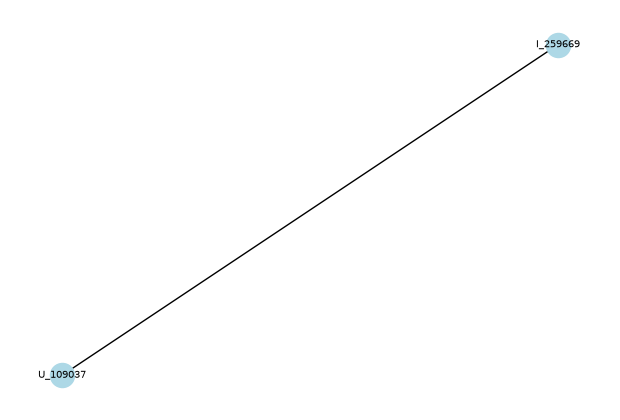

In [49]:
import networkx as nx
import matplotlib.pyplot as plt

q_sebelum = """
MATCH (u:Visitor {visitorId: 109037})-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
RETURN u.visitorId AS User, i.itemId AS Item LIMIT 15
"""

G_sebelum = nx.Graph()
with driver.session() as session:
    for row in session.run(q_sebelum):
        G_sebelum.add_edge(f"U_{row['User']}", f"I_{row['Item']}")

plt.figure(figsize=(6, 4))
nx.draw(G_sebelum, node_size=300, node_color='lightblue', with_labels=True, font_size=7)
plt.show()

After

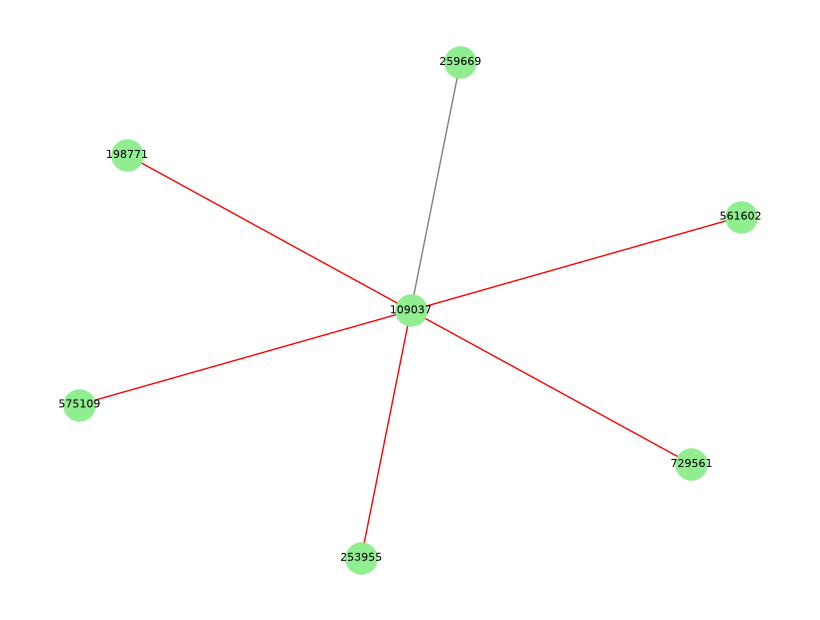

In [50]:
import networkx as nx
import matplotlib.pyplot as plt

q_sesudah = """
MATCH (u:Visitor {visitorId: 109037})-[r:VIEWED|ADDED_TO_CART|BOUGHT|SIMILAR_TO]-(x)
RETURN DISTINCT u.visitorId AS U, coalesce(x.itemId, x.visitorId) AS X, type(r) AS R
"""

G_sesudah = nx.Graph()
with driver.session() as session:
    for row in session.run(q_sesudah):
        warna = 'red' if row['R'] == 'SIMILAR_TO' else 'gray'
        G_sesudah.add_edge(f"{row['U']}", f"{row['X']}", color=warna)

colors = [G_sesudah[u][v]['color'] for u, v in G_sesudah.edges()]

plt.figure(figsize=(8, 6))
nx.draw(G_sesudah, node_size=500, node_color='lightgreen', edge_color=colors, with_labels=True, font_size=8)
plt.show()